# 02  PyTorch CNN
CNN side of the project. Loads the data, trains the CNN, and tests it on clean and degraded images.

### 1. Setup


Change `DRIVE_DATA_ROOT` to wherever your copy of the dataset is (the folder with `Train.csv`, `Test.csv`, `Train/` and `Test/`). If it's in "Shared with me", add a shortcut to My Drive first. Local runs use `Dataset/raw/` instead. Set `USE_DRIVE = False` to use the repo data in Colab.

In [1]:
import sys
from pathlib import Path

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# USE_DRIVE = IN_COLAB
USE_DRIVE = False

# CHANGE THIS ONE DATASET PATH to your own shared Drive folder/shortcut:
DRIVE_DATA_ROOT = "/content/drive/MyDrive/CP467_Traffic_Signs/data/raw"
print("Running in Colab:", IN_COLAB)
print("Python:", sys.version)

Running in Colab: True
Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


### Mount Drive + get the code
Opening the notebook from GitHub doesn't bring the `src/` files with it, so this clones the repo if it can't find it.

In [2]:
import os
import subprocess

if USE_DRIVE and IN_COLAB:
    drive.mount("/content/drive")

PROJECT_ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "src" / "config.py").is_file() and (p / "requirements.txt").is_file()),
    None,
)
if PROJECT_ROOT is None and IN_COLAB:
    PROJECT_ROOT = Path("/content/CP467GroupProject")
    if not PROJECT_ROOT.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1",
             "https://github.com/Davy-Chu/CP467GroupProject.git", str(PROJECT_ROOT)],
            check=True,
        )
if PROJECT_ROOT is None or not (PROJECT_ROOT / "src" / "config.py").is_file():
    raise RuntimeError("Open from the project checkout or change directory to its root first.")

os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /content/CP467GroupProject


### Dependencies
Colab already has most of these. Only set `INSTALL_DEPENDENCIES = True` if an import fails, then restart the runtime and set it back to False.

In [3]:
INSTALL_DEPENDENCIES = False
if INSTALL_DEPENDENCIES:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-r", str(PROJECT_ROOT / "requirements.txt")],
        check=True,
    )

import cv2
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import skimage
import sklearn
import torch
import torchvision
import seaborn

for library in (cv2, np, pd, matplotlib, skimage, sklearn, torch, torchvision, seaborn):
    print(f"{library.__name__}: {library.__version__}")

cv2: 5.0.0
numpy: 2.4.6
pandas: 2.2.3
matplotlib: 3.10.0
skimage: 0.25.2
sklearn: 1.6.1
torch: 2.14.1+cpu
torchvision: 0.29.1+cpu
seaborn: 0.13.2


In [4]:
%pip install -q kagglehub

In [5]:
# from src.config import (
#     NUM_CLASSES, IMAGE_SIZE, RANDOM_SEED, REPO_DATA_ROOT,
#     RESULTS_DIR, MODELS_DIR, CONDITIONS, DEGRADATION_PARAMS,
#     get_data_root, seed_everything,
# )
# from src.data_utils import (
#     validate_dataset, load_metadata, load_image,
#     make_train_validation_split, split_fingerprint,
# )
# from src.degradations import (
#     apply_condition, reduce_brightness, add_noise, apply_motion_blur,
#     equalize_histogram, gaussian_filter,
# )

# seed_everything()
# DATA_ROOT = get_data_root(USE_DRIVE, DRIVE_DATA_ROOT)
# print("Selected data root:", DATA_ROOT)
# print("Repository fallback:", REPO_DATA_ROOT)
# print("Shared conditions:", DEGRADATION_PARAMS)



import kagglehub

from src.config import (
    NUM_CLASSES, IMAGE_SIZE, RANDOM_SEED, REPO_DATA_ROOT,
    RESULTS_DIR, MODELS_DIR, CONDITIONS, DEGRADATION_PARAMS,
    get_data_root, seed_everything,
)
from src.data_utils import (
    validate_dataset, load_metadata, load_image,
    make_train_validation_split, split_fingerprint,
)
from src.degradations import (
    apply_condition, reduce_brightness, add_noise, apply_motion_blur,
    equalize_histogram, gaussian_filter,
)

seed_everything()

#Download full GTSRB dataset
DATA_ROOT = Path(kagglehub.dataset_download(
    "meowmeowmeowmeowmeow/gtsrb-german-traffic-sign"
))

print("Selected data root:", DATA_ROOT)
print("Repository fallback:", REPO_DATA_ROOT)
print("Shared conditions:", DEGRADATION_PARAMS)


Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
Selected data root: /kaggle/input/gtsrb-german-traffic-sign
Repository fallback: /content/CP467GroupProject/Dataset/raw
Shared conditions: {'brightness': {'factor': 0.5}, 'noise': {'std': 0.05}, 'motion_blur': {'kernel_size': 9}}


## 2. GPU / Device Check
Switch the Colab runtime to GPU before training (Runtime > Change runtime type). CPU works but training is slow.

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
if device.type == "cuda":
    print(torch.cuda.get_device_name(0))
else:
    print("CPU selected. Enable a Colab GPU before CNN training if available.")

cpu
CPU selected. Enable a Colab GPU before CNN training if available.


## 3. Load Dataset

Checks that all 43 classes and all 39,209 train / 12,630 test images are there. By default it only opens one image per class, use `check_images="all"` for a full check (slow).

In [7]:
# make sure this passes before training anything
training_metadata, test_metadata = validate_dataset(DATA_ROOT, check_images="sample")
train_metadata, validation_metadata = make_train_validation_split(training_metadata)
SPLIT_ID = split_fingerprint(train_metadata, validation_metadata)
print(f"Training subset: {len(train_metadata):,}")
print(f"Validation subset: {len(validation_metadata):,}")
print(f"Official test (final evaluation only): {len(test_metadata):,}")
print("Split ID (must match across teammates):", SPLIT_ID)

Dataset root: /kaggle/input/gtsrb-german-traffic-sign
Train/: 39,209 PNG images present (expected 39,209).
Decoding 43 Train images (sample check)...
Train.csv: 39,209 rows, 43 classes.
Test/: 12,630 PNG images present (expected 12,630).
Decoding 43 Test images (sample check)...
Test.csv: 12,630 rows, 43 classes.
Dataset validation passed (image decoding: sample).
Training subset: 31,367
Validation subset: 7,842
Official test (final evaluation only): 12,630
Split ID (must match across teammates): 43b66458595c7cd9


## 4. DataLoader Setup
Apply `apply_condition` to the common resized RGB image before converting to tensors. Reuse optional shared preprocessing helpers; never augment validation/test randomly.



In [8]:
from torch.utils.data import TensorDataset, DataLoader

# load the whole split into the memory once, this si faster than reading pngs from every epoch
# def load_split_into_memory(metadata, condition="clean"):
def load_split_into_memory(metadata, condition="clean", preprocessing="none"):
    images = []
    labels = []
    for i in range(len(metadata)):
        path = metadata.iloc[i].Path
        img = load_image(DATA_ROOT, path)
        img = apply_condition(img, condition, image_id=path)


        #Apply optional preprocessing
        if preprocessing == "equalize":
            img = equalize_histogram(img)
        elif preprocessing == "gaussian":
            img = gaussian_filter(img, kernel_size=3, sigma=1.0)
        elif preprocessing != "none":
            raise ValueError(f"Unknown preprocessing: {preprocessing}")


        images.append(img)
        labels.append(metadata.iloc[i].ClassId)
    images =np.array(images)
    labels = np.array(labels)

    # Since pytorch expects flaots o-1 and channels first (N,C,H, W):
    x = images.astype(np.float32) / 255.0
    x = torch.from_numpy(x)
    x = x.permute(0, 3, 1, 2)
    y = torch.from_numpy(labels).long()
    return x, y

x_train, y_train = load_split_into_memory(train_metadata, condition="clean")
print(f"Train loaded: {x_train.shape}")

x_val, y_val = load_split_into_memory(validation_metadata, condition="clean")
print(f"Validation loaded: {x_val.shape}")

# Only shuffle the training, seeded to rerun come in the same order
g = torch.Generator()
g.manual_seed(RANDOM_SEED)
train_dataset = TensorDataset(x_train, y_train)
val_dataset = TensorDataset(x_val, y_val)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, generator=g)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)


Train loaded: torch.Size([31367, 3, 32, 32])
Validation loaded: torch.Size([7842, 3, 32, 32])


## 5. CNN Architecture

In [9]:
import torch.nn as nn

# 3 Conversion blocks, in each one it finds features then halves the size of the iamge

class TrafficCnn(nn.Module):
    def __init__(self):
        super().__init__()
        #block 1 3 colour channels go in, 32 filters out 32x32 becomes 16x16
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        #block 2: 16x16 becomes 8x8, 32 filters go in, 64 filters out
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        #block 3: 8x8 becomes 4x4, 64 filters go in, 128 filters out
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3 , padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        self.relu = nn.ReLU()
        #After 3 poools we have 128 channels of 4x4
        self.fc1 = nn.Linear(128 * 4 * 4, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, NUM_CLASSES)

    def forward(self, x):
        x = self.conv1(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv2(x)
        x = self.relu(x)
        x = self.pool(x)
        x = self.conv3(x)
        x = self.relu(x)
        x = self.pool(x)

        x= torch.flatten(x, 1) # 128x4x4 -> 2048 long vector
        x = self.fc1(x)
        x = self.relu(x)
        x = self.dropout(x)
        x = self.fc2(x) # 43 scores, one per sign class
        return x

model = TrafficCnn()
model.to(device)

#Count the weights for the report
total_params = 0
for p in model.parameters():
    total_params += p.numel()
print(f"Total parameters: {total_params:,}")

Total parameters: 628,843


## 6. Training

In [10]:
import time
import copy

EPOCHS = 10
LEARNING_RATE = 0.001

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# msave every epoch so that curves can be plotted in section 7
train_losses = []
val_losses = []
train_accs = []
val_accs = []

best_val_acc = 0.0

best_epoch = 0
best_weights = None

# gpu runs async so sync before starting the timer
if device.type == "cuda":
    torch.cuda.synchronize()
start_time = time.perf_counter()

for epoch in range(EPOCHS):
    # train part
    model.train()  # turns the dropout on
    running_loss = 0.0
    correct = 0
    total = 0
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()  # clear all of the gradients from the last batch
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss = running_loss + loss.item() * images.size(0)
        preds = outputs.argmax(dim=1)
        correct = correct + (preds == labels).sum().item()
        total = total + labels.size(0)
    train_loss = running_loss / total
    train_acc = correct / total

    # val part, no gradients needed
    model.eval()  # turns dropout off
    running_loss = 0.0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)

            running_loss = running_loss + loss.item() * images.size(0)
            preds = outputs.argmax(dim=1)
            correct = correct + (preds == labels).sum().item()
            total = total + labels.size(0)
    val_loss = running_loss / total
    val_acc = correct / total

    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)

    # keep a copy of the best epoch so far
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        best_weights = copy.deepcopy(model.state_dict())

    print(f"epoch {epoch + 1}/{EPOCHS}: train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}")

if device.type == "cuda":
    torch.cuda.synchronize()
training_time = time.perf_counter() - start_time
print(f"Time training took: {training_time:.1f} s")
print(f"Best epoch {best_epoch} with val acc: {best_val_acc:.4f}")

epoch 1/10: train loss 2.4002 acc 0.2930 | val loss 1.3420 acc 0.5315
epoch 2/10: train loss 1.0148 acc 0.6573 | val loss 0.4141 acc 0.8738
epoch 3/10: train loss 0.4502 acc 0.8501 | val loss 0.1703 acc 0.9583
epoch 4/10: train loss 0.2467 acc 0.9218 | val loss 0.0925 acc 0.9776
epoch 5/10: train loss 0.1686 acc 0.9459 | val loss 0.0728 acc 0.9793
epoch 6/10: train loss 0.1239 acc 0.9602 | val loss 0.0459 acc 0.9897
epoch 7/10: train loss 0.0984 acc 0.9682 | val loss 0.0411 acc 0.9902
epoch 8/10: train loss 0.0831 acc 0.9734 | val loss 0.0355 acc 0.9918
epoch 9/10: train loss 0.0728 acc 0.9764 | val loss 0.0354 acc 0.9922
epoch 10/10: train loss 0.0613 acc 0.9797 | val loss 0.0285 acc 0.9936
Time training took: 723.5 s
Best epoch 10 with val acc: 0.9936


## 7. Validation

Loaded  in best weights from epoch #10 (val acc 0.9936)


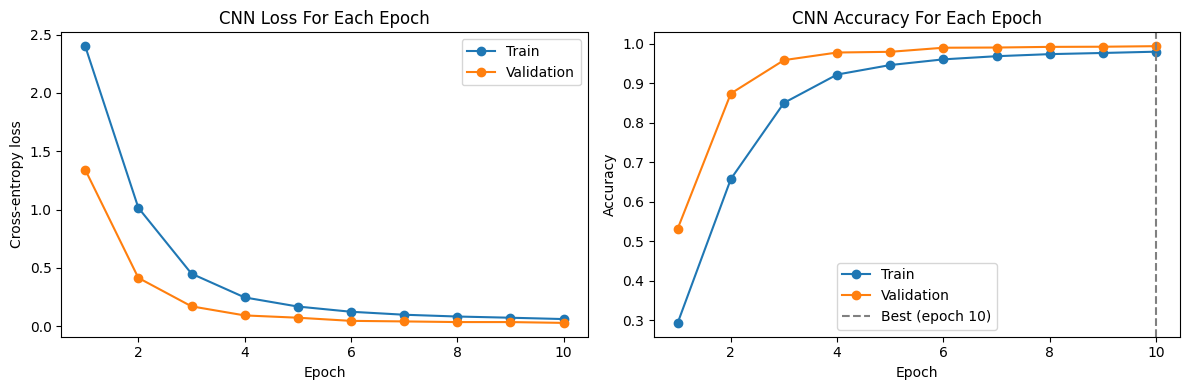

In [11]:
# place the best epoch back in so that the testing uses it, but not epoch 10
model.load_state_dict(best_weights)
model.eval()

print(f"Loaded  in best weights from epoch #{best_epoch} (val acc {best_val_acc:.4f})")

PLOTS_DIR = RESULTS_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

epoch_nums = []
for e in range(EPOCHS):
    epoch_nums.append(e + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left side is the  loss
axes[0].plot(epoch_nums, train_losses, marker="o", label="Train")
axes[0].plot(epoch_nums, val_losses, marker="o", label="Validation")
axes[0].set_title("CNN Loss For Each Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()

# right side is the accuracy the dashed line marks the epoch that we kept
axes[1].plot(epoch_nums, train_accs, marker="o", label="Train")
axes[1].plot(epoch_nums, val_accs, marker="o", label="Validation")
axes[1].axvline(best_epoch, color="gray", linestyle="--", label=f"Best (epoch {best_epoch})")
axes[1].set_title("CNN Accuracy For Each Epoch")
axes[1].set_xlabel("Epoch")

axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.savefig(PLOTS_DIR / "cnn_training_curves.png", dpi=150)
plt.show()

## 8. Clean Test Evaluation

In [12]:
from sklearn.metrics import accuracy_score, f1_score

BATCH_SIZE = 64

# run the model on a whole split and give back the predicted class for each image

# function since we can reuse it for clean + 3 degraed test sets
def predict(x):
    dataset = TensorDataset(x)
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
    all_preds = []
    model.eval() # Dropout ius off otherwise the results will change every time its ran
    with torch.no_grad(): #not training so no need to calculate the gradients, it wil waste time and memory
        for batch in loader:
            images = batch[0]
            images = images.to(device)
            outputs = model(images)    #43 scores per image
            preds = outputs.argmax(dim=1)
            preds = preds.cpu()  # back to cpu so numpy can utilize it
            all_preds.append(preds)
    all_preds = torch.cat(all_preds)
    all_preds = all_preds.numpy()
    return all_preds

# Test set, only use this since training is done
x_test_clean, y_test = load_split_into_memory(test_metadata, condition="clean")
print(f"Test loaded: {x_test_clean.shape}")
y_true = y_test.numpy()

clean_preds = predict(x_test_clean)

# same metric settings as the svm side so numbers are comparable
all_labels = list(range(NUM_CLASSES))
clean_acc = accuracy_score(y_true, clean_preds)
clean_f1 = f1_score(y_true, clean_preds, average="macro", labels=all_labels, zero_division=0)
print(f"clean test: accuracy {clean_acc:.4f}, macro f1 {clean_f1:.4f}")

# one entry per condition, these go into metrics.csv in section 12
test_results = []
clean_result = {}
clean_result["condition"] = "clean"
clean_result["accuracy"] = clean_acc
clean_result["macro_f1"] = clean_f1
test_results.append(clean_result)

# keep the images and predictions per condition for the sample outputs figure later
test_imgs = {}
test_preds = {}
test_imgs["clean"] = x_test_clean
test_preds["clean"] = clean_preds

Test loaded: torch.Size([12630, 3, 32, 32])
clean test: accuracy 0.9454, macro f1 0.9283


## 9. Degraded Test Evaluation

brightness test: accuracy 0.9264, macro f1 0.8987
noise test: accuracy 0.8947, macro f1 0.8706
motion_blur test: accuracy 0.8108, macro f1 0.7428

clean: accuracy 0.9454, macro f1 0.9283, drop 0.0000
brightness: accuracy 0.9264, macro f1 0.8987, drop 0.0191
noise: accuracy 0.8947, macro f1 0.8706, drop 0.0508
motion_blur: accuracy 0.8108, macro f1 0.7428, drop 0.1347


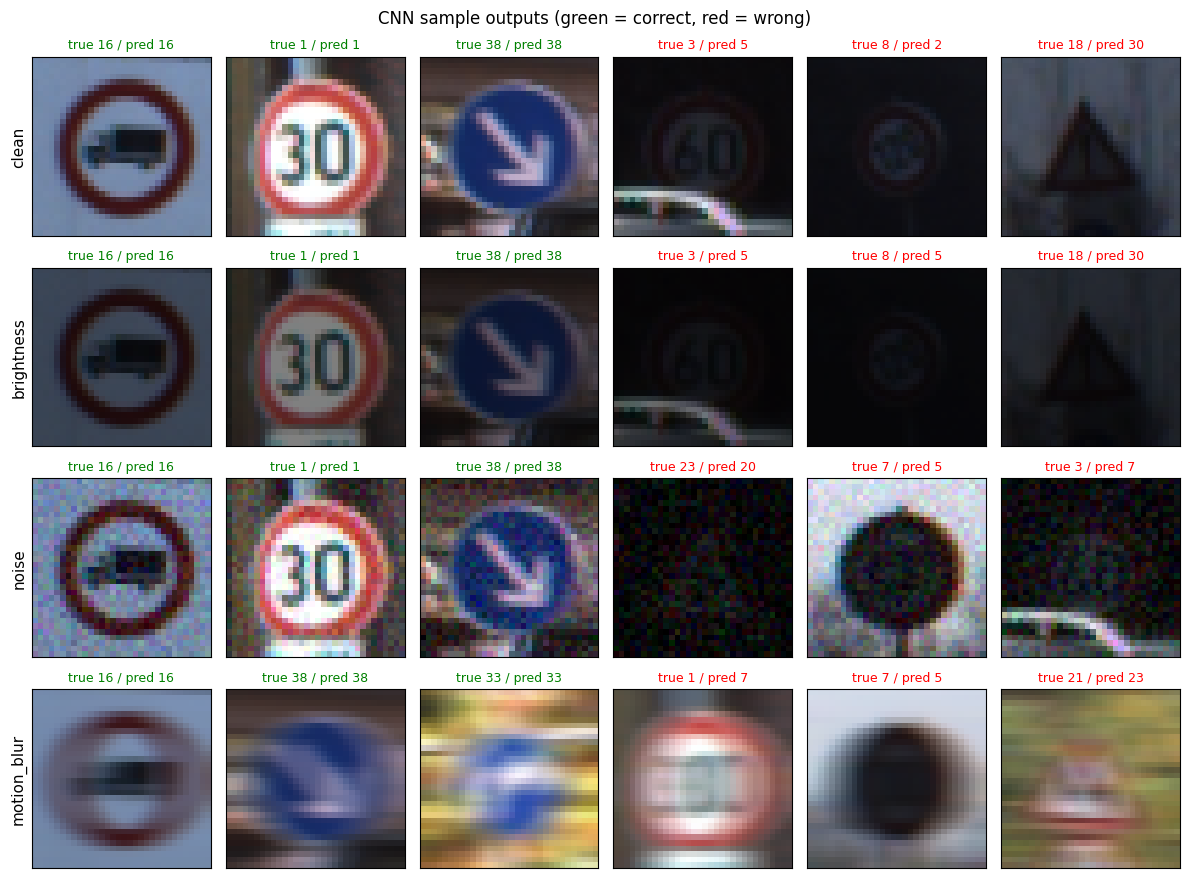

In [13]:
# Constants to show per row in the original sample figure
NUM_RIGHT = 3
NUM_WRONG = 3

# The same test images but made darker / noisy / blurry
# Apply_condition seeds the noise with the image path so the svm side gets the exact same noise
for condition in CONDITIONS:
    if condition == "clean":
        continue  # already did clean in section 8

    # y_test_cond is the same as y_test, labels dont change with degradation
    x_test_cond, y_test_cond = load_split_into_memory(test_metadata, condition=condition)
    cond_preds = predict(x_test_cond)

    cond_acc = accuracy_score(y_true, cond_preds)
    cond_f1 = f1_score(y_true, cond_preds, average="macro", labels=all_labels, zero_division=0)
    print(f"{condition} test: accuracy {cond_acc:.4f}, macro f1 {cond_f1:.4f}")

    cond_result = {}
    cond_result["condition"] = condition
    cond_result["accuracy"] = cond_acc
    cond_result["macro_f1"] = cond_f1
    test_results.append(cond_result)

    test_imgs[condition] = x_test_cond
    test_preds[condition] = cond_preds

# Summarize, the drop = how much accuracy we lost vs clean
print()
for result in test_results:
    drop = clean_acc - result["accuracy"]
    print(f"{result['condition']}: accuracy {result['accuracy']:.4f}, macro f1 {result['macro_f1']:.4f}, drop {drop:.4f}")

# sample outputs for the report: first 3 right and first 3 wrong for each condition
fig, axes = plt.subplots(len(CONDITIONS), NUM_RIGHT + NUM_WRONG, figsize=(12, 9))

for row in range(len(CONDITIONS)):
    condition = CONDITIONS[row]
    preds = test_preds[condition]

    right_idx = []
    wrong_idx = []
    for i in range(len(y_true)):
        if preds[i] == y_true[i] and len(right_idx) < NUM_RIGHT:
            right_idx.append(i)
        if preds[i] != y_true[i] and len(wrong_idx) < NUM_WRONG:
            wrong_idx.append(i)
    picked = right_idx + wrong_idx

    for col in range(len(picked)):
        i = picked[col]
        img = test_imgs[condition][i]
        img = img.permute(1, 2, 0)  # =back to (H,W,C) so matplotlib can show it
        img = img.numpy()

        ax = axes[row, col]
        ax.imshow(img)
        # Hide ticks but not the whole axis, otherwise the row label disappears
        ax.set_xticks([])
        ax.set_yticks([])

        if preds[i] == y_true[i]:
            color = "green"
        else:
            color = "red"
        ax.set_title(f"true {y_true[i]} / pred {preds[i]}", color=color, fontsize=9)

    axes[row, 0].set_ylabel(condition, fontsize=11)

fig.suptitle("CNN sample outputs (green = correct, red = wrong)")
plt.tight_layout()
plt.savefig(PLOTS_DIR / "cnn_sample_outputs.png", dpi=150)
plt.show()

In [14]:

#Evaluate CNN using same conditions as HOG + SVM
experiments = [
    ("clean", "none"),
    ("brightness", "none"),
    ("noise", "none"),
    ("motion_blur", "none"),
    ("brightness", "equalize"),
    ("noise", "gaussian"),
]

results = []
class_ids = sorted(validation_metadata["ClassId"].unique())

for condition, preprocessing in experiments:
    x, y = load_split_into_memory(
        validation_metadata,
        condition=condition,
        preprocessing=preprocessing,
    )

    predictions = predict(x)
    labels = y.numpy()

    accuracy = accuracy_score(labels, predictions)
    macro_f1 = f1_score(
        labels,
        predictions,
        labels=class_ids,
        average="macro",
        zero_division=0,
    )

    results.append({
        "condition": condition,
        "preprocessing": preprocessing,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
    })

    print(
        f"{condition} ({preprocessing}) | "
        f"Accuracy={accuracy:.4f} | F1={macro_f1:.4f}"
    )

    del x, y

#Calculate accuracy drop
degradation_results = pd.DataFrame(results)

clean_accuracy = degradation_results.loc[
    degradation_results["condition"] == "clean",
    "accuracy",
].iloc[0]

degradation_results["accuracy_drop"] = (
    clean_accuracy - degradation_results["accuracy"]
)

display(degradation_results)


clean (none) | Accuracy=0.9936 | F1=0.9921
brightness (none) | Accuracy=0.9860 | F1=0.9845
noise (none) | Accuracy=0.9527 | F1=0.9579
motion_blur (none) | Accuracy=0.8952 | F1=0.8728
brightness (equalize) | Accuracy=0.8397 | F1=0.8261
noise (gaussian) | Accuracy=0.9510 | F1=0.9522


,condition,preprocessing,accuracy,macro_f1,accuracy_drop
0,clean,none,0.993624,0.992065,0.000000
1,brightness,none,0.985973,0.984510,0.007651
2,noise,none,0.952691,0.957880,0.040933
3,motion_blur,none,0.895180,0.872778,0.098444
4,brightness,equalize,0.839709,0.826079,0.153915
5,noise,gaussian,0.951033,0.952197,0.042591


## 10. Timing

In [15]:
#Constant for how many times to run the inference timing
NUM_TIMING_RUNS = 3

# The first gpu call is always slow because the cuda needs to warm up so do a test run first
warmup_preds = predict(x_test_clean)
# time the whole clean test set a few times and average it
# only times the model, not loading pngs, svm side should do the same
run_times = []
for run in range(NUM_TIMING_RUNS):
    if device.type == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    timing_preds = predict(x_test_clean)


    if device.type == "cuda":
        torch.cuda.synchronize()  # wait for the gpu to actually finish
    end = time.perf_counter()
    run_times.append(end - start)
    print(f"run {run + 1}: {end - start:.3f} s")

average_time = sum(run_times) / len(run_times)
num_images = len(x_test_clean)
inference_ms = average_time / num_images * 1000  # the seconds per image -> ms per image

print(f"Training time: {training_time:.1f}s")

if device.type == "cuda":
    hardware = torch.cuda.get_device_name(0)
else:
    hardware = "cpu"
print(f"Inference: {inference_ms:.4f} ms per image (batch {BATCH_SIZE}, {hardware})")

run 1: 12.166 s
run 2: 12.134 s
run 3: 12.135 s
Training time: 723.5s
Inference: 0.9616 ms per image (batch 64, cpu)


In [16]:

#Measure end-to-end inference time
def measure_inference_time(metadata, max_images=20):
    times = []

    for i in range(min(max_images, len(metadata))):
        sample = metadata.iloc[i:i+1]

        if device.type == "cuda":
            torch.cuda.synchronize()

        start = time.perf_counter()

        x, _ = load_split_into_memory(sample)

        with torch.no_grad():
            model(x.to(device)).argmax(dim=1).cpu()

        if device.type == "cuda":
            torch.cuda.synchronize()

        elapsed = time.perf_counter() - start
        times.append(elapsed)

    return {
        "num_images": len(times),
        "average_ms": np.mean(times) * 1000,
        "median_ms": np.median(times) * 1000,
        "total_seconds": np.sum(times),
    }


#Warm up model
predict(x_val[:1])

#Use same validation images as HOG
timing_results = measure_inference_time(
    validation_metadata,
    max_images=20,
)

print("Images tested:", timing_results["num_images"])
print(f"Average end-to-end inference: {timing_results['average_ms']:.4f} ms/image")
print(f"Median end-to-end inference: {timing_results['median_ms']:.4f} ms/image")


Images tested: 20
Average end-to-end inference: 3.2169 ms/image
Median end-to-end inference: 2.7671 ms/image


## 11. Confusion Matrix

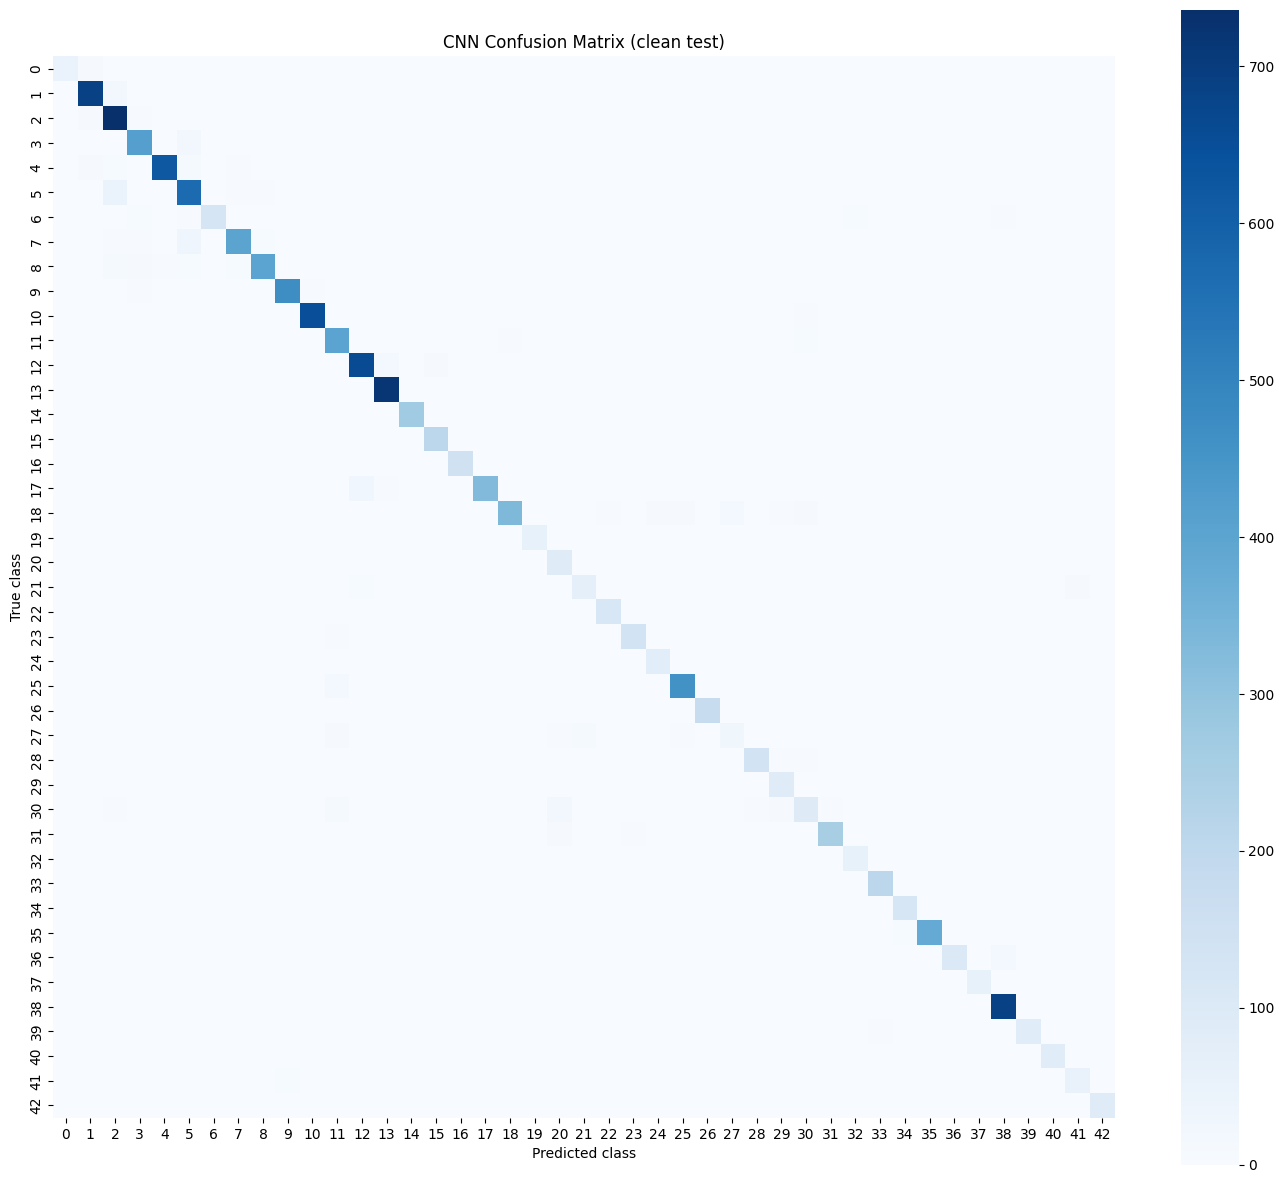

True 5 predicted as 2: 46 times
True 7 predicted as 5: 33 times
True 17 predicted as 12: 26 times
True 3 predicted as 5: 25 times
True 1 predicted as 2: 24 times


In [17]:
from sklearn.metrics import confusion_matrix

CM_DIR = RESULTS_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

# Rows = true class, columns = what the model guessed, diagonal = correct
cm = confusion_matrix(y_true, clean_preds, labels=all_labels)

fig, ax = plt.subplots(figsize=(14, 12))
# no numbers in the boxes, 43x43 is way too crowded
seaborn.heatmap(cm, cmap="Blues", square=True, xticklabels=all_labels, yticklabels=all_labels, ax=ax)
ax.set_title("CNN Confusion Matrix (clean test)")
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
plt.tight_layout()
plt.savefig(CM_DIR / "cnn_clean.png", dpi=150)
plt.show()

# The plot is mostly diagonal so also list the biggest mistakes for the report
mistakes = []
for t in range(NUM_CLASSES):
    for p in range(NUM_CLASSES):
        if t != p and cm[t, p] > 0:
            mistakes.append((cm[t, p], t, p))
mistakes.sort(reverse=True)  # biggest count comes first


for k in range(5):
    count = mistakes[k][0]
    t = mistakes[k][1]
    p = mistakes[k][2]
    print(f"True {t} predicted as {p}: {count} times")

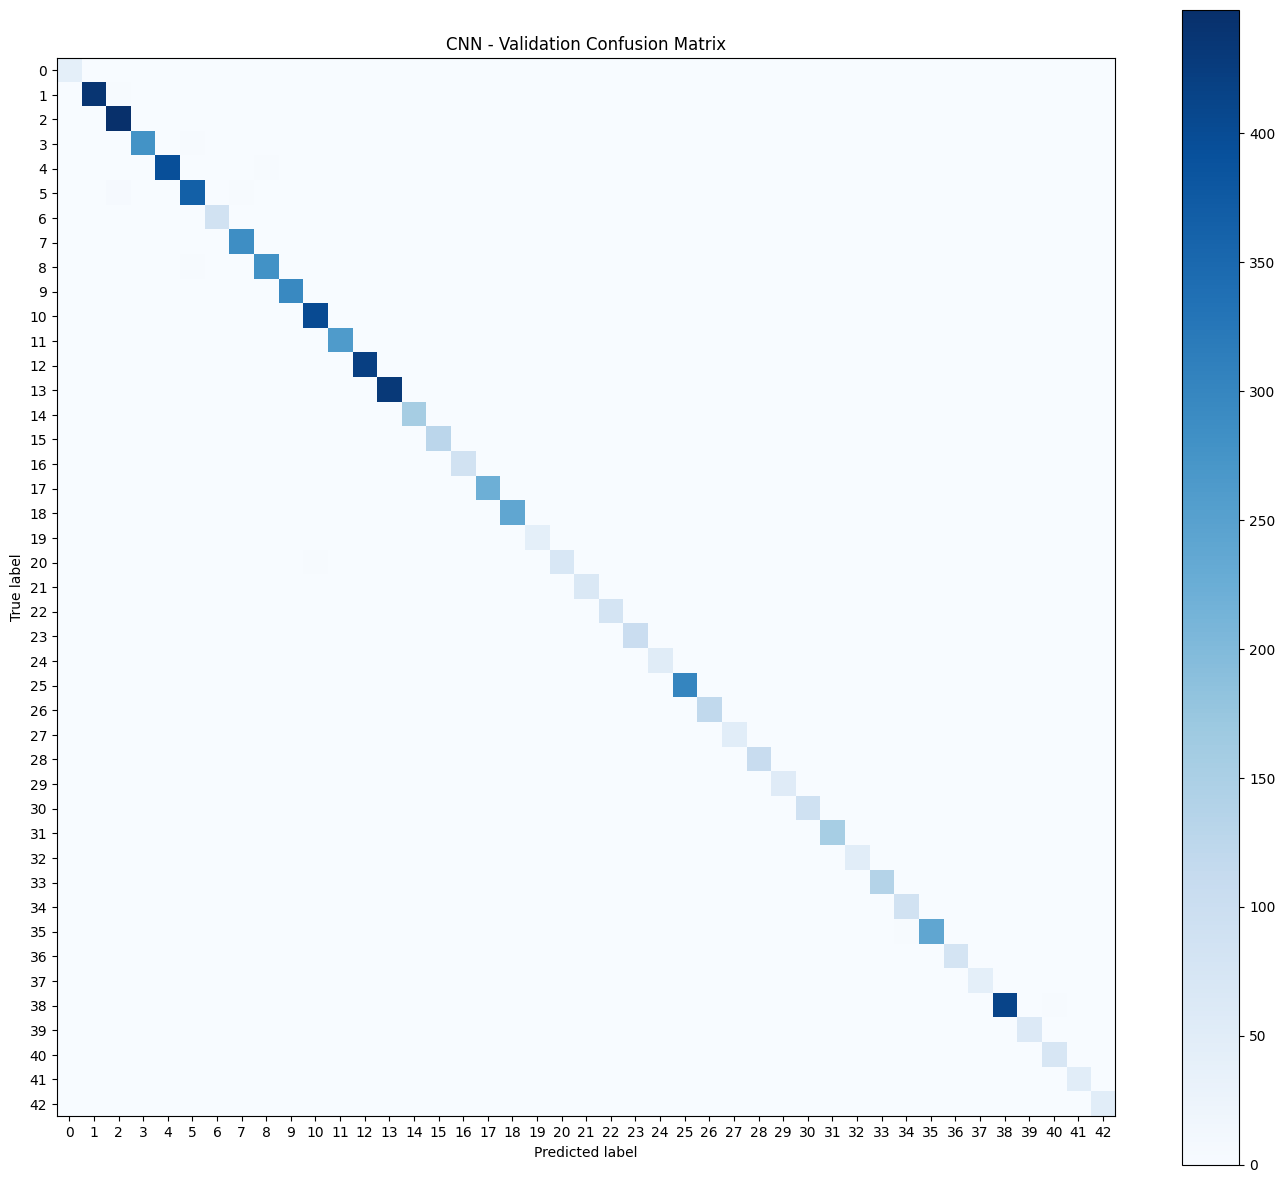

Confusion matrix saved: /content/CP467GroupProject/results/figures/cnn_validation_confusion_matrix.png


In [18]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Generate validation predictions
validation_predictions = predict(x_val)

matrix = confusion_matrix(
    y_val.numpy(),
    validation_predictions,
    labels=class_ids,
)

fig, ax = plt.subplots(figsize=(14, 12))

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=class_ids,
).plot(
    ax=ax,
    cmap="Blues",
    include_values=False,
)

ax.set_title("CNN - Validation Confusion Matrix")
plt.tight_layout()

save_path = RESULTS_DIR / "figures" / "cnn_validation_confusion_matrix.png"
save_path.parent.mkdir(parents=True, exist_ok=True)

fig.savefig(save_path, dpi=200, bbox_inches="tight")

plt.show()
plt.close(fig)

print("Confusion matrix saved:", save_path)


## 12. Save Model / Results


In [19]:
# #Constants, need to remember to change PREPROCESSING later when we test hist eq / gaussian
# MODEL_NAME = "cnn"
# PREPROCESSING = "none"
# MODEL_PATH = MODELS_DIR / "cnn.pt"
# METRICS_PATH = RESULTS_DIR / "metrics.csv"

# # save just the weights (state_dict), smaller and the normal way to do it
# MODELS_DIR.mkdir(parents=True, exist_ok=True)
# torch.save(model.state_dict(), MODEL_PATH)
# size_mb = MODEL_PATH.stat().st_size / 1024 / 1024
# print(f"saved model to {MODEL_PATH} ({size_mb:.2f} MB)")

# # add one row per condition, the header is already in the file so dont write it again
# # newline="" so windows doesnt sneak \r into the file for everyone else
# with open(METRICS_PATH, "a", newline="") as f:
#     for result in test_results:
#         row = []
#         row.append(MODEL_NAME)
#         row.append(result["condition"]) #
#         row.append(PREPROCESSING)
#         row.append(f"{result['accuracy']:.4f}")
#         row.append(f"{result['macro_f1']:.4f}")
#         row.append(f"{training_time:.1f}")
#         row.append(f"{inference_ms:.4f}")  # timed on clean, speed doesnt change with condition
#         row.append(str(RANDOM_SEED))
#         row.append(SPLIT_ID)
#         line = ",".join(row) # csv of values
#         f.write(line + "\n")
#         print(line)



import json

#Create output directories
results_dir = RESULTS_DIR / "metrics"
figures_dir = RESULTS_DIR / "figures"

results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

#Save degradation results
final_results = degradation_results.copy()
final_results.insert(0, "model", "CNN")

final_results.to_csv(
    results_dir / "cnn_metrics.csv",
    index=False,
)

#Save model configuration
configuration = {
    "model": "CNN",
    "random_seed": RANDOM_SEED,
    "image_size": list(IMAGE_SIZE),
    "num_classes": NUM_CLASSES,
    "split_id": SPLIT_ID,
    "degradation_parameters": DEGRADATION_PARAMS,
    "epochs": EPOCHS,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "best_epoch": best_epoch,
    "best_validation_accuracy": best_val_acc,
    "training_time_seconds": training_time,
    "timing": timing_results,
    "device": str(device),
    "evaluation_split": "validation",
}

with open(results_dir / "cnn_config.json", "w") as file:
    json.dump(configuration, file, indent=2, default=str)

#Save training history
training_history = pd.DataFrame({
    "epoch": range(1, EPOCHS + 1),
    "train_loss": train_losses,
    "validation_loss": val_losses,
    "train_accuracy": train_accs,
    "validation_accuracy": val_accs,
})

training_history.to_csv(
    results_dir / "cnn_training_history.csv",
    index=False,
)

#Save trained CNN
torch.save(model.state_dict(), MODELS_DIR / "cnn.pt")

print("Saved metrics, configuration, and trained model.")

display(final_results)


Saved metrics, configuration, and trained model.


,model,condition,preprocessing,accuracy,macro_f1,accuracy_drop
0,CNN,clean,none,0.993624,0.992065,0.000000
1,CNN,brightness,none,0.985973,0.984510,0.007651
2,CNN,noise,none,0.952691,0.957880,0.040933
3,CNN,motion_blur,none,0.895180,0.872778,0.098444
4,CNN,brightness,equalize,0.839709,0.826079,0.153915
5,CNN,noise,gaussian,0.951033,0.952197,0.042591


In [20]:

import shutil
from pathlib import Path
from google.colab import files

#Create export folders
export_dir = Path("/content/cnn_export")

if export_dir.exists():
    shutil.rmtree(export_dir)

(export_dir / "models").mkdir(parents=True)
(export_dir / "results" / "metrics").mkdir(parents=True)
(export_dir / "results" / "figures").mkdir(parents=True)

#Copy trained model
shutil.copy2(
    MODELS_DIR / "cnn.pt",
    export_dir / "models" / "cnn.pt",
)

#Copy metrics and configuration
for filename in [
    "cnn_metrics.csv",
    "cnn_config.json",
    "cnn_training_history.csv",
]:
    shutil.copy2(
        RESULTS_DIR / "metrics" / filename,
        export_dir / "results" / "metrics" / filename,
    )

#Copy confusion matrix
shutil.copy2(
    save_path,
    export_dir / "results" / "figures" / save_path.name,
)

#Copy additional plots
for filename in [
    "cnn_training_curves.png",
    "cnn_sample_outputs.png",
]:
    shutil.copy2(
        PLOTS_DIR / filename,
        export_dir / "results" / "figures" / filename,
    )

#Create ZIP file
shutil.make_archive(
    "/content/cnn_export",
    "zip",
    export_dir,
)

#Show files
print("=== FILES READY ===")

for path in export_dir.rglob("*"):
    if path.is_file():
        print(path.relative_to(export_dir))

#Download ZIP
files.download("/content/cnn_export.zip")


=== FILES READY ===
models/cnn.pt
results/metrics/cnn_config.json
results/metrics/cnn_metrics.csv
results/metrics/cnn_training_history.csv
results/figures/cnn_training_curves.png
results/figures/cnn_validation_confusion_matrix.png
results/figures/cnn_sample_outputs.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>